Preguntas propuestas para el proyecto BiciTierra_Market:

Qué tipo de bicis se venden más en cada campaña? -> Para saber que se vende por campaña

Qué tipos de bicis se venden más en cada región? -> Para saber donde hacer cada campaña

In [148]:
import pandas as pd
pd.plotting.register_matplotlib_converters()
import matplotlib.pyplot as plt
%matplotlib inline

df_sales_history = pd.read_csv('../data/originales/sales_history.csv', parse_dates=True, date_format='%m-%Y')

df_sales_history.isnull().sum()



month                   0
channel                 0
product_line            0
region                  0
marketing_spend        18
avg_discount           24
stock_units             0
website_sessions       18
sales_units             0
revenue                 0
marketing_budget       12
planned_discount       12
list_price              0
campaign                0
days_in_month           0
closing_stock_units     0
stockout                0
dtype: int64

Marketing_spend nos sirve en un futuro para saber si se están gastando de más en ciertas lineas de producto y ver si renta si se está gastando de más del budget permitido




In [149]:
# Selección de las columnas definidas para los cálculos por campaña y región
COLUMNAS = ['month', 'channel', 'product_line', 'region', 'sales_units', 'revenue', 'campaign']
df_sales_new = df_sales_history.reset_index()[COLUMNAS]

# El período en texto se convierte en año y mes numérico para agrupar por temporada
periodo = pd.to_datetime(df_sales_new['month'])
df_sales_new['year'] = periodo.dt.year
df_sales_new['month'] = periodo.dt.month
df_sales_new = df_sales_new[['year'] + COLUMNAS]

df_sales_new

,year,month,channel,product_line,region,sales_units,revenue,campaign
0,2021,1,store,urban,coast,95,38024.70,none
1,2021,1,store,urban,inland,82,31891.44,none
2,2021,1,store,urban,metro,141,56259.00,none
3,2021,1,store,mountain,coast,56,37210.32,none
4,2021,1,store,mountain,inland,44,27293.64,none
...,...,...,...,...,...,...,...,...
1183,2026,6,ecommerce,mountain,inland,96,69895.68,none
1184,2026,6,ecommerce,mountain,metro,198,143407.44,none
1185,2026,6,ecommerce,electric,coast,92,137376.00,none
1186,2026,6,ecommerce,electric,inland,53,82164.45,none


In [150]:
# Agregación por año: las filas de cada año se juntan sumando las medidas

# Que tipo de bicis se venden mas en cada región
DIMENSIONES = ['year',  'product_line', 'region']
MEDIDAS = ['sales_units', 'revenue']

df_sales_year_region = (
    df_sales_new.groupby(DIMENSIONES, as_index=False)[MEDIDAS]
    .sum()
    .sort_values(DIMENSIONES)
    .reset_index(drop=True)
)

df_sales_year_region.head(10)

,year,product_line,region,sales_units,revenue
0,2021,electric,coast,1266,1741118.70
1,2021,electric,inland,868,1182856.38
2,2021,electric,metro,1443,1995504.49
3,2021,mountain,coast,2289,1476104.77
4,2021,mountain,inland,1561,997983.00
5,2021,mountain,metro,2633,1664549.58
6,2021,urban,coast,3383,1306566.89
7,2021,urban,inland,2336,910194.54
8,2021,urban,metro,4151,1616250.10
9,2022,electric,coast,1381,1924881.18


In [151]:
# Que tipo de bicis se venden mas en cada campaña
DIMENSIONES = ['year',  'product_line', 'campaign']
MEDIDAS = ['sales_units', 'revenue']

df_sales_year_campaign = (
    df_sales_new.groupby(DIMENSIONES, as_index=False)[MEDIDAS]
    .sum()
    .sort_values(DIMENSIONES)
    .reset_index(drop=True)
)

df_sales_year_campaign

,year,product_line,campaign,sales_units,revenue
0,2021,electric,black_friday,292,367013.17
1,2021,electric,christmas,271,354177.89
2,2021,electric,none,2502,3549797.53
3,2021,electric,spring,177,222431.05
4,2021,electric,summer,335,426059.93
...,...,...,...,...,...
76,2026,electric,spring,486,699215.92
77,2026,mountain,none,3596,2568406.81
78,2026,mountain,spring,554,359964.59
79,2026,urban,none,4790,2091827.46


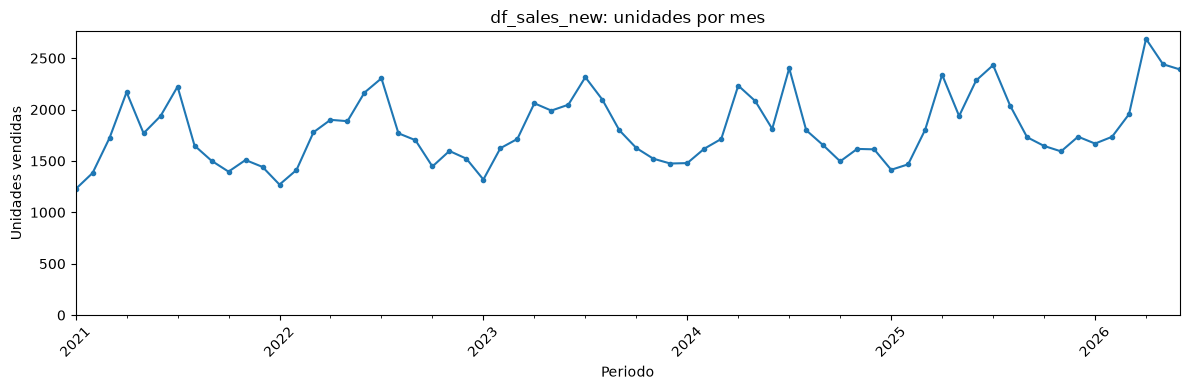

In [152]:
# Gráfica de líneas: unidades por mes del dataframe mensual
periode = pd.to_datetime(df_sales_new[['year', 'month']].assign(day=1))
mensual = df_sales_new.groupby(periode)['sales_units'].sum()

mensual.plot(figsize=(12, 4), marker='o', markersize=3)
plt.title('df_sales_new: unidades por mes')
plt.xlabel('Periodo')
plt.ylabel('Unidades vendidas')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

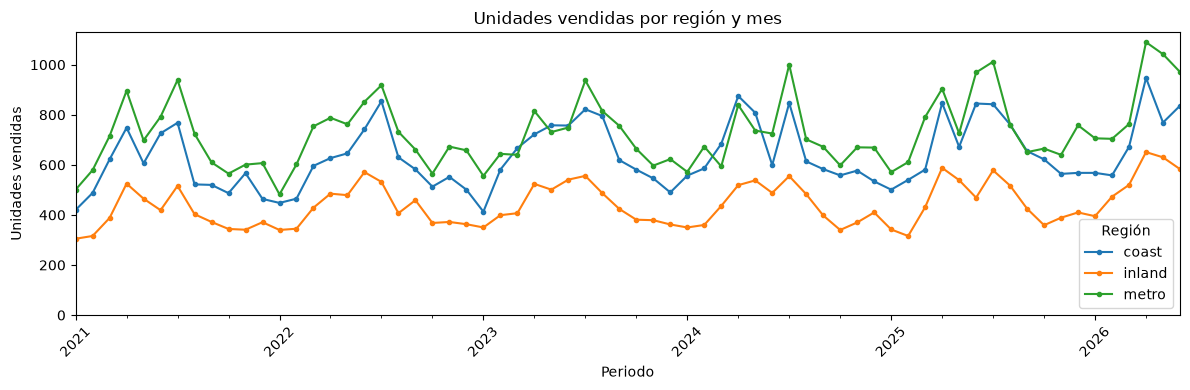

In [153]:
# Gráfica de líneas: unidades vendidas por región a lo largo de los meses
regions = df_sales_new.groupby([periode, 'region'])['sales_units'].sum().unstack()

regions.plot(figsize=(12, 4), marker='o', markersize=3)
plt.title('Unidades vendidas por región y mes')
plt.xlabel('Periodo')
plt.ylabel('Unidades vendidas')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.legend(title='Región')
plt.tight_layout()
plt.show()

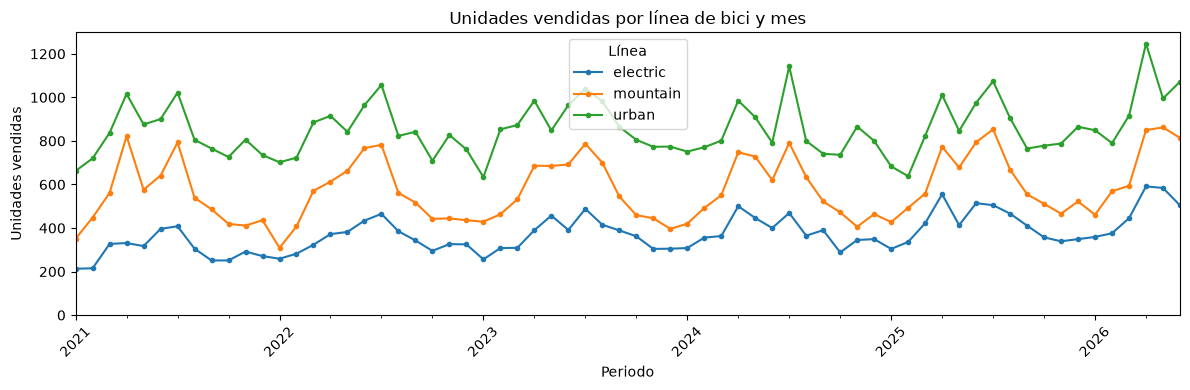

In [154]:
# Gráfica de líneas: evolución mensual de cada línea de bici
linies = df_sales_new.groupby([periode, 'product_line'])['sales_units'].sum().unstack()

linies.plot(figsize=(12, 4), marker='o', markersize=3)
plt.title('Unidades vendidas por línea de bici y mes')
plt.xlabel('Periodo')
plt.ylabel('Unidades vendidas')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.legend(title='Línea')
plt.tight_layout()
plt.show()

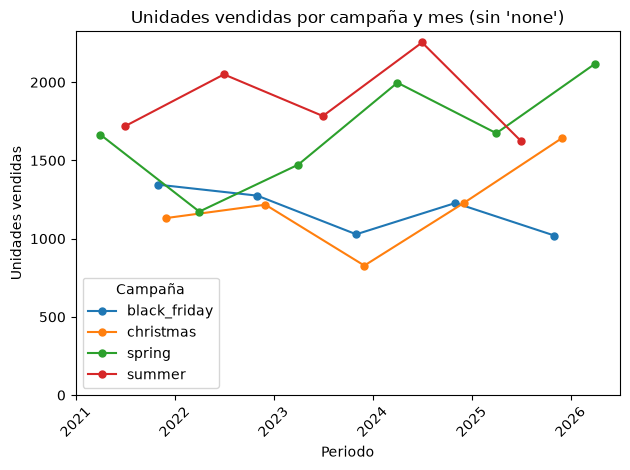

In [155]:
# Gráfica de líneas: solo las campañas reales, uniendo con una línea los meses con venta
campanyes = df_sales_new.groupby([periode, 'campaign'])['sales_units'].sum().unstack()

for nom, serie in campanyes.drop(columns='none').items():
    plt.plot(serie.dropna(), marker='o', markersize=5, label=nom)

plt.title("Unidades vendidas por campaña y mes (sin 'none')")
plt.xlabel('Periodo')
plt.ylabel('Unidades vendidas')
plt.ylim(bottom=0)
plt.xticks(rotation=45)
plt.legend(title='Campaña')
plt.tight_layout()
plt.show()

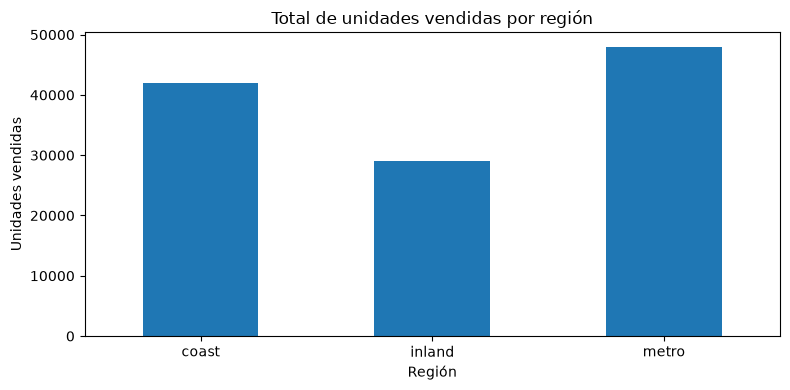

In [156]:
# Gráfico de barras: total de unidades por región (dataframe regions)
regions.sum().plot(kind='bar', figsize=(8, 4))
plt.title("Total de unidades vendidas por región")
plt.xlabel('Región')
plt.ylabel('Unidades vendidas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

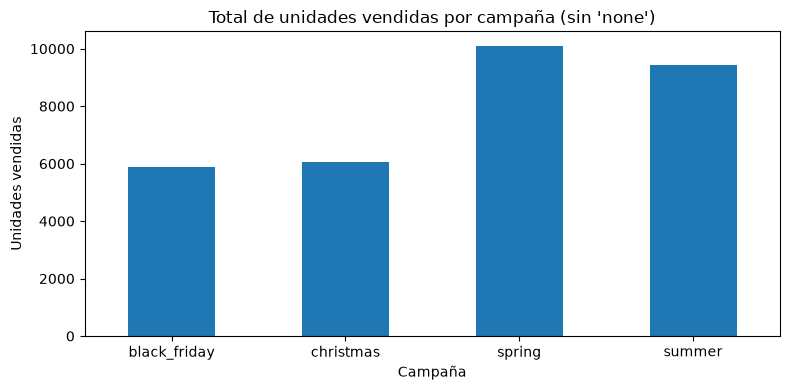

In [157]:
# Gráfico de barras: solo las campañas reales, sin la venta sin campaña ('none')
campanyes.drop(columns='none').sum().plot(kind='bar', figsize=(8, 4))
plt.title("Total de unidades vendidas por campaña (sin 'none')")
plt.xlabel('Campaña')
plt.ylabel('Unidades vendidas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Respuesta a las preguntas del proyecto

Gráficas pensadas para responder las dos preguntas del principio: qué tipo de bici vende más en cada campaña y qué tipo de bici vende más en cada región.

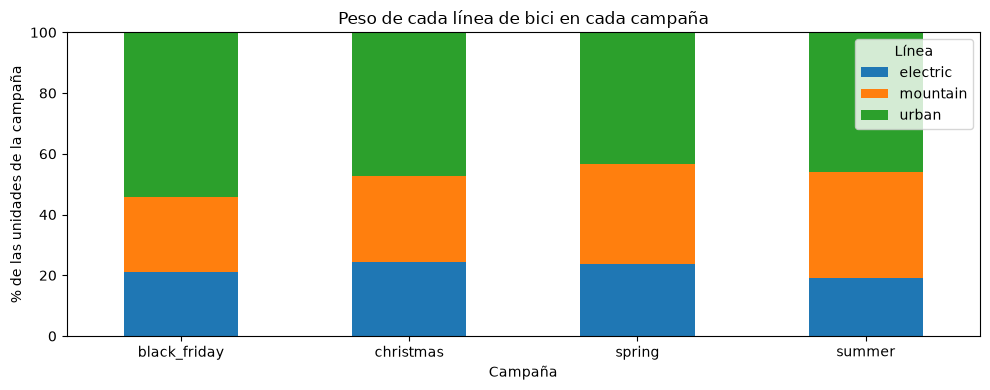

product_line,electric,mountain,urban
campaign,,,
black_friday,21.0,24.8,54.2
christmas,24.2,28.4,47.3
spring,23.6,33.2,43.2
summer,19.1,35.1,45.9


In [158]:
# Pregunta 1: qué tipo de bici domina cada campaña (porcentaje dentro de cada campaña)
linies_campanya = (
    df_sales_new[df_sales_new['campaign'] != 'none']
    .groupby(['campaign', 'product_line'])['sales_units'].sum()
    .unstack()
)
linies_campanya_pct = linies_campanya.div(linies_campanya.sum(axis=1), axis=0) * 100

linies_campanya_pct.plot(kind='bar', stacked=True, figsize=(10, 4))
plt.title('Peso de cada línea de bici en cada campaña')
plt.xlabel('Campaña')
plt.ylabel('% de las unidades de la campaña')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Línea')
plt.tight_layout()
plt.show()

linies_campanya_pct.round(1)

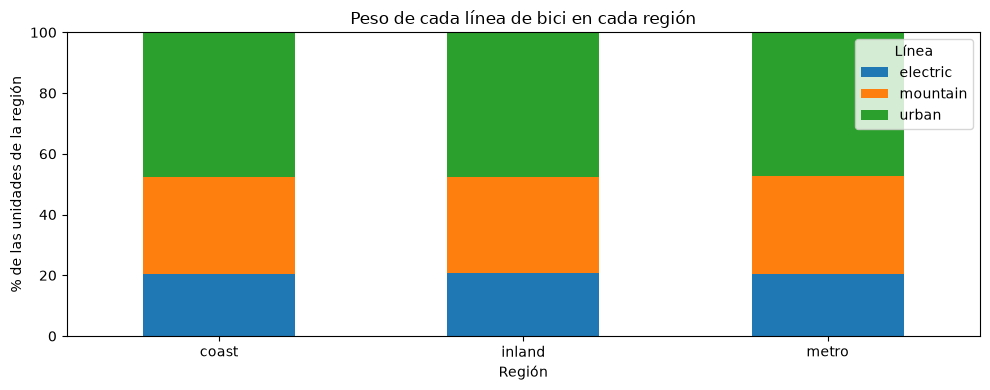

product_line,electric,mountain,urban
region,,,
coast,20.6,31.9,47.5
inland,20.8,31.7,47.5
metro,20.6,32.3,47.2


In [159]:
# Pregunta 2: qué tipo de bici domina cada región (porcentaje dentro de cada región)
linies_regio = df_sales_new.groupby(['region', 'product_line'])['sales_units'].sum().unstack()
linies_regio_pct = linies_regio.div(linies_regio.sum(axis=1), axis=0) * 100

linies_regio_pct.plot(kind='bar', stacked=True, figsize=(10, 4))
plt.title('Peso de cada línea de bici en cada región')
plt.xlabel('Región')
plt.ylabel('% de las unidades de la región')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Línea')
plt.tight_layout()
plt.show()

linies_regio_pct.round(1)

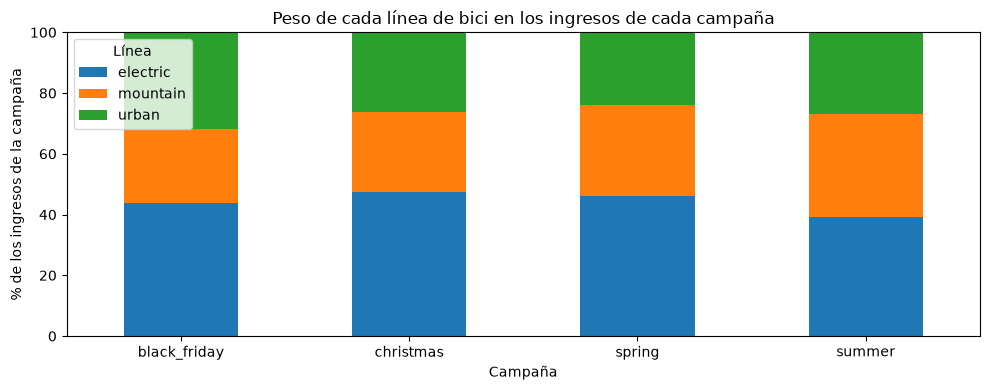

product_line,electric,mountain,urban
campaign,,,
black_friday,1632205.0,903328.0,1181189.0
christmas,1957768.0,1080628.0,1083331.0
spring,3215608.0,2081971.0,1667808.0
summer,2371332.0,2040775.0,1625960.0


In [160]:
# Pregunta 1 en ingresos: qué genera cada tipo de bici en cada campaña
linies_campanya_revenue = (
    df_sales_new[df_sales_new['campaign'] != 'none']
    .groupby(['campaign', 'product_line'])['revenue'].sum()
    .unstack()
)
linies_campanya_revenue_pct = linies_campanya_revenue.div(linies_campanya_revenue.sum(axis=1), axis=0) * 100

linies_campanya_revenue_pct.plot(kind='bar', stacked=True, figsize=(10, 4))
plt.title('Peso de cada línea de bici en los ingresos de cada campaña')
plt.xlabel('Campaña')
plt.ylabel('% de los ingresos de la campaña')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Línea')
plt.tight_layout()
plt.show()

linies_campanya_revenue.round(0)

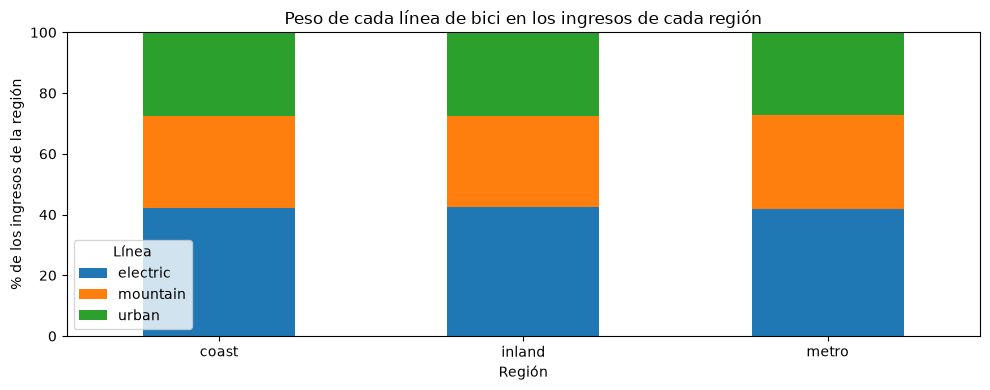

product_line,electric,mountain,urban
region,,,
coast,12407438.0,8998763.0,8095771.0
inland,8686036.0,6151970.0,5635616.0
metro,14118998.0,10334580.0,9217042.0


In [161]:
# Pregunta 2 en ingresos: qué genera cada tipo de bici en cada región
linies_regio_revenue = df_sales_new.groupby(['region', 'product_line'])['revenue'].sum().unstack()
linies_regio_revenue_pct = linies_regio_revenue.div(linies_regio_revenue.sum(axis=1), axis=0) * 100

linies_regio_revenue_pct.plot(kind='bar', stacked=True, figsize=(10, 4))
plt.title('Peso de cada línea de bici en los ingresos de cada región')
plt.xlabel('Región')
plt.ylabel('% de los ingresos de la región')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Línea')
plt.tight_layout()
plt.show()

linies_regio_revenue.round(0)